# Medicare Telehealth Access: where virtual care stuck, and for whom

**Business question:** after the pandemic surge, how much do Medicare patients still use telehealth, and which states and patient groups depend on it most? A health system leader can use the answers to size virtual capacity and decide whom to protect if telehealth rules change after December 31, 2027.

**Data:** CMS [Medicare Telehealth Trends](https://data.cms.gov/summary-statistics-on-use-and-payments/medicare-medicaid-service-type-reports/medicare-telehealth-trends), public aggregate data, 2020 Q1 to 2026 Q1, Medicare fee-for-service only. Rate = beneficiaries with a telehealth service / telehealth-eligible users. Every number below is computed from the SQLite database built by `run_all.py`.

In [1]:
import sys, json
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / 'src'))
import pandas as pd, matplotlib.pyplot as plt
import build_db, findings
from paths import REPORTS
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
TEAL, ORANGE, GREY = '#12806f', '#e07a1f', '#9aa8ae'
con = build_db.connect()
F = findings.compute()
M = F['metrics']
print('Latest quarter:', F['latest_period'])

Latest quarter: 2026-Q1


## Data quality
Checks run by `src/clean.py` before anything is analyzed (full report: `reports/data_quality.md`).

In [2]:
dq = pd.DataFrame(json.loads((REPORTS / 'data_quality.json').read_text()))
pd.set_option('display.max_colwidth', 120)
dq[['severity', 'check', 'detail']]

,severity,check,detail
0,ok,schema,"13 columns: ['Year', 'quarter', 'Bene_Geo_Desc', 'Bene_Mdcd_Mdcr_Enrl_Stus', 'Bene_Race_Desc', 'Bene_Sex_Desc', 'Ben..."
1,ok,geographies,"56 geographies (50 states + DC, PR, VI, other territories, National, Missing Data); unexpected=[] absent=[]"
2,ok,unique key,"0 duplicate rows on ['Year', 'quarter', 'Bene_Geo_Desc', 'Bene_RUCA_Desc', 'Bene_Age_Desc', 'Bene_Race_Desc', 'Bene_..."
3,ok,period coverage,"each geography has [31] distinct periods (2020-2026, quarters 1-4 plus annual 'Overall')"
4,ok,suppressed cells,"4,026 of 37,324 rows have no rate (suppressed or not applicable). Mostly 'Unknown' rural/urban and 'Other/Unknown' r..."
5,ok,rate within 0-1,min=0.0000 max=0.8202
6,ok,users <= eligible,0 rows where telehealth users exceed eligible users
7,ok,rate = users / eligible,max absolute difference 0.000050 (CMS rounds to 4 decimals)
8,ok,states sum to national,sum of geographies / national eligible users ranges 0.9998-1.0000
9,warning,eligible-user jumps >20% q/q,1 state-quarters: ['Vermont 2026-Q1 (+27%)']. Kept as published; treat with care.


## 1. National trend: a surge, then a steady base

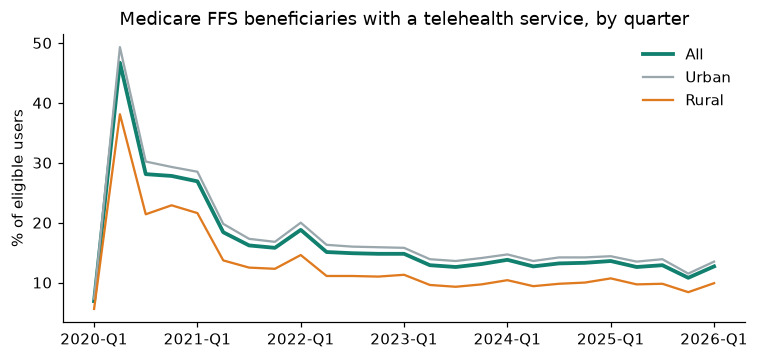

Peak 46.7% in 2020-Q2; latest 12.7% in 2026-Q1
2023 onward range: 10.8 - 14.8


In [3]:
nat = build_db.query('07_national_trend', con)
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(nat.period, nat.pct_telehealth, color=TEAL, lw=2.5, label='All')
ax.plot(nat.period, nat.urban_pct, color=GREY, lw=1.5, label='Urban')
ax.plot(nat.period, nat.rural_pct, color=ORANGE, lw=1.5, label='Rural')
ax.set_xticks(range(0, len(nat), 4), nat.period[::4]); ax.set_ylabel('% of eligible users'); ax.legend(frameon=False)
ax.set_title('Medicare FFS beneficiaries with a telehealth service, by quarter'); plt.show()
peak = nat.loc[nat.pct_telehealth.idxmax()]
print(f"Peak {peak.pct_telehealth}% in {peak.period}; latest {nat.pct_telehealth.iloc[-1]}% in {nat.period.iloc[-1]}")
print('2023 onward range:', nat[nat.year >= 2023].pct_telehealth.min(), '-', nat[nat.year >= 2023].pct_telehealth.max())

## 2. State rankings: a fourfold spread

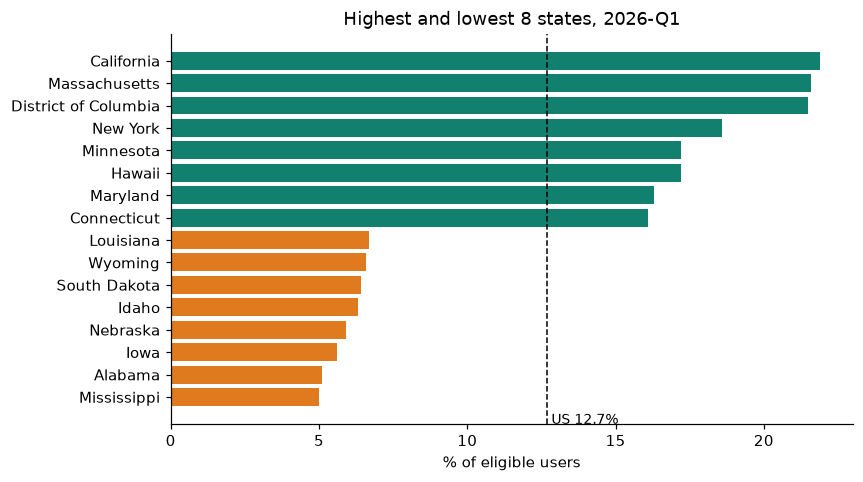

California 21.9% vs Mississippi 5.0% = 4.4x; 16 of 51 above national


In [4]:
rk = build_db.query('01_state_rankings', con)
show = pd.concat([rk.head(8), rk.tail(8)])
fig, ax = plt.subplots(figsize=(8, 4.6))
ax.barh(show.geo[::-1], show.pct_telehealth[::-1], color=[TEAL if r <= 8 else ORANGE for r in show.rank_high_to_low[::-1]])
us = nat.pct_telehealth.iloc[-1]; ax.axvline(us, color='k', ls='--', lw=1); ax.text(us, -1.2, f' US {us}%', fontsize=9)
ax.set_xlabel('% of eligible users'); ax.set_title(f"Highest and lowest 8 states, {rk.period.iloc[0]}"); plt.show()
print(f"{rk.geo.iloc[0]} {rk.pct_telehealth.iloc[0]}% vs {rk.geo.iloc[-1]} {rk.pct_telehealth.iloc[-1]}% "
      f"= {M['geography']['ratio']:.1f}x; {M['geography']['n_above_national']} of 51 above national")

In [5]:
chg = build_db.query('02_change_vs_peak_and_2024', con)
chg[['geo', 'peak_period', 'peak_pct', 'same_qtr_2024_pct', 'latest_pct', 'pct_of_peak_retained', 'pp_vs_2024']].head(10)

,geo,peak_period,peak_pct,same_qtr_2024_pct,latest_pct,pct_of_peak_retained,pp_vs_2024
0,California,2020-Q2,55.3,26.0,21.9,40.0,-4.0
1,Hawaii,2020-Q2,44.1,21.1,17.2,39.0,-3.9
2,District of Columbia,2020-Q2,59.9,22.2,21.5,36.0,-0.7
3,New York,2020-Q2,55.7,19.1,18.6,33.0,-0.5
4,Minnesota,2020-Q2,55.0,16.9,17.2,31.0,0.4
5,Washington,2020-Q2,42.1,14.9,12.5,30.0,-2.4
6,Alaska,2020-Q2,45.7,15.0,13.0,29.0,-2.0
7,Massachusetts,2020-Q2,73.5,21.3,21.6,29.0,0.3
8,Colorado,2020-Q2,44.7,13.8,12.5,28.0,-1.3
9,Florida,2020-Q2,43.1,12.4,12.2,28.0,-0.3


## 3. Rural vs urban gap by state

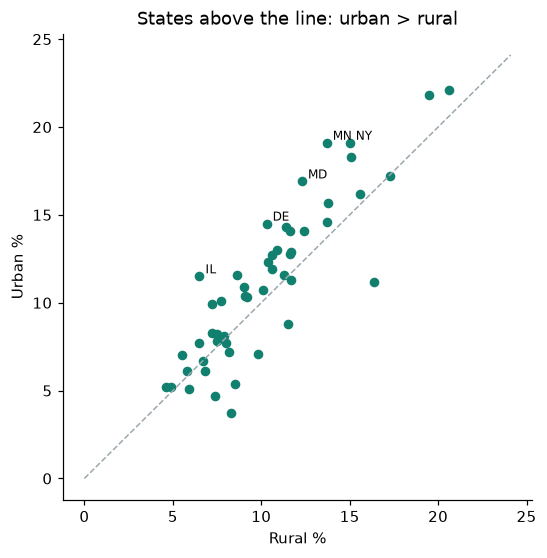

Rural lower than urban in 37 of 50 states; national gap 3.5 pts


,period,geo_code,geo,rural_pct,urban_pct,gap_pp,urban_to_rural_ratio,rural_eligible_users
0,2026-Q1,MN,Minnesota,13.7,19.1,5.4,1.39,106780
1,2026-Q1,IL,Illinois,6.5,11.5,5.0,1.76,170464
2,2026-Q1,MD,Maryland,12.3,16.9,4.5,1.37,68280
3,2026-Q1,DE,Delaware,10.3,14.5,4.3,1.41,51279
4,2026-Q1,NY,New York,15.0,19.1,4.1,1.27,149143


In [6]:
ru = build_db.query('03_rural_urban_gap', con)
st = ru[ru.geo_code != 'US']
fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.scatter(st.rural_pct, st.urban_pct, color=TEAL, s=28)
lim = [0, max(st.urban_pct.max(), st.rural_pct.max()) + 2]; ax.plot(lim, lim, color=GREY, ls='--', lw=1)
for r in st.nlargest(5, 'gap_pp').itertuples(): ax.annotate(r.geo_code, (r.rural_pct, r.urban_pct), xytext=(4, 2), textcoords='offset points', fontsize=8)
ax.set_xlabel('Rural %'); ax.set_ylabel('Urban %'); ax.set_title('States above the line: urban > rural'); plt.show()
print(f"Rural lower than urban in {(st.gap_pp > 0).sum()} of {len(st)} states; national gap {ru[ru.geo_code=='US'].gap_pp.iloc[0]} pts")
st.head(5)

## 4. Age gradient: under-65 (disability/ESRD) beneficiaries lead

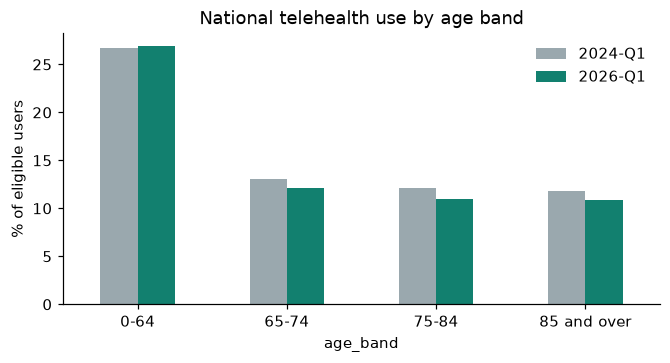

period,2024-Q1,2026-Q1
age_band,,
0-64,26.7,26.9
65-74,13.1,12.1
75-84,12.1,11.0
85 and over,11.8,10.9


In [7]:
ag = build_db.query('04_age_gradient', con)
n = ag[ag.geo_code == 'US'].pivot(index='age_band', columns='period', values='pct_telehealth')
ax = n.plot.bar(figsize=(7, 3.2), color=[GREY, TEAL], rot=0); ax.set_ylabel('% of eligible users')
ax.set_title('National telehealth use by age band'); ax.legend(frameon=False); plt.show()
n

## 5. Equity: dual status and race/ethnicity

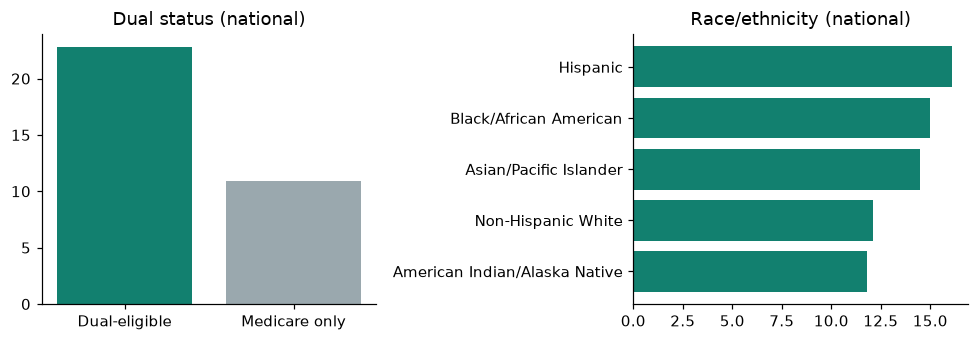

Dual-eligible higher than Medicare-only in 51 of 51 states


,period,race_ethnicity,pct_telehealth,pp_vs_white,eligible_users
0,2026-Q1,Hispanic,16.1,4.0,1152314
1,2026-Q1,Black/African American,15.0,2.9,1393263
2,2026-Q1,Asian/Pacific Islander,14.5,2.4,657226
3,2026-Q1,Non-Hispanic White,12.1,0.0,17547792
4,2026-Q1,American Indian/Alaska Native,11.8,-0.3,92029
5,2024-Q1,Asian/Pacific Islander,18.5,5.4,645910
6,2024-Q1,Hispanic,18.0,4.9,1121279
7,2024-Q1,Black/African American,15.4,2.3,1452776
8,2024-Q1,American Indian/Alaska Native,13.3,0.2,96305
9,2024-Q1,Non-Hispanic White,13.1,0.0,17468081


In [8]:
ds = build_db.query('06_equity_dual_status', con)
race = build_db.query('05_equity_race_ethnicity', con)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(9, 3.2))
usd = ds[ds.geo_code == 'US'].iloc[0]
a1.bar(['Dual-eligible', 'Medicare only'], [usd.dual_pct, usd.medicare_only_pct], color=[TEAL, GREY]); a1.set_title('Dual status (national)')
lat = race[race.period == race.period.max()]
a2.barh(lat.race_ethnicity[::-1], lat.pct_telehealth[::-1], color=TEAL); a2.set_title('Race/ethnicity (national)')
plt.tight_layout(); plt.show()
print(f"Dual-eligible higher than Medicare-only in {(ds[ds.geo_code!='US'].gap_pp > 0).sum()} of {len(ds)-1} states")
race

## Findings for a health system leader
Generated by `src/findings.py` from the same database; the app's Insights tab and the README use this exact text.

In [9]:
from IPython.display import Markdown
Markdown('\n\n'.join(f"**{i}. {f['title']}** ({f['stat']} {f['stat_label']})\n\n{f['text']}\n\n*So what:* {f['so_what']}" for i, f in enumerate(F['findings'], 1)))

**1. Telehealth settled at a steady base, it did not disappear** (12.7% of eligible Medicare FFS users, 2026-Q1)

National use peaked at 46.7% in 2020-Q2. Since 2023 it has held between 10.8% and 14.8% a quarter, and was 12.7% in 2026-Q1 (-1.1 pts vs 2024-Q1), about 2.7 million people. The low point since 2020 was 10.8% in 2025-Q4.

*So what:* Plan virtual capacity as a permanent, steady share of visits rather than a pandemic surge that is still unwinding.

**2. Where a patient lives changes telehealth use by more than 4x** (4.4x California vs Mississippi)

In 2026-Q1, California led at 21.9% and Mississippi was lowest at 5.0%. Only 16 of 51 states (incl. DC) beat the national rate. Highest: California, Massachusetts, District of Columbia, New York, Minnesota. Lowest: Mississippi, Alabama, Iowa, Nebraska, Idaho.

*So what:* Benchmark virtual share against your own state, not the national average, before setting targets.

**3. Rural patients use telehealth less than urban patients** (-3.5 pts rural vs urban, national)

Nationally 9.9% of rural vs 13.5% of urban eligible users had a telehealth service in 2026-Q1. Rural use was lower in 37 of 50 states with both groups reported (DC has no rural ZIP codes); the widest gap was Minnesota (13.7% rural vs 19.1% urban).

*So what:* Rural outreach needs more than a video link: audio-only options, broadband help and scheduling support are where the gap can close.

**4. Under-65 beneficiaries with disabilities are the heaviest users** (26.9% of under-65 eligible users)

Beneficiaries under 65 (Medicare through disability or ESRD) used telehealth at 26.9%, 2.2x the 65-74 rate (12.1%). Use edges down with age: 11.0% at 75-84 and 10.9% at 85+. By entitlement, Disabled 27.3%, ESRD 19.9%, Aged 11.4%.

*So what:* Protect virtual access for patients with disabilities and ESRD first; they would feel any policy rollback most.

**5. Dual-eligible (low-income) beneficiaries use telehealth 2.1x as often as Medicare-only** (2.1x dual-eligible vs Medicare-only)

Dual-eligible (Medicare & Medicaid) beneficiaries used telehealth at 22.8% vs 10.9% for Medicare-only, higher in 51 of 51 states. By race/ethnicity, Hispanic beneficiaries were highest at 16.1% and American Indian/Alaska Native lowest at 11.8% (Non-Hispanic White 12.1%).

*So what:* Track virtual share by payer and demographic group in clinic dashboards; a cut to telehealth falls hardest on dual-eligible patients.

In [10]:
# Cross-check: the SQL outputs agree with the findings module
assert abs(nat.pct_telehealth.iloc[-1] - M['plateau']['latest'] * 100) < 0.051
assert rk.geo.iloc[0] == M['geography']['top_state'] and rk.geo.iloc[-1] == M['geography']['bottom_state']
assert (st.gap_pp > 0).sum() == M['rural']['n_rural_lower']
assert abs(usd.dual_pct - M['equity']['dual'] * 100) < 0.051
print('All cross-checks passed')

All cross-checks passed
